# Lab 2: Sentinel-2 download, cloud masking, gap filling and feature composites (Python)

Python port of Lab 2 (Class 5). Each ArcGIS step from the handout is quoted word for word (the quote blocks), followed by a short **In Python** note on how it is done here and where Python does it differently.

Same three parts as the original:

1. **Download** Sentinel-2 L2A from the Copernicus Data Space Ecosystem, via its OData API instead of the Browser.
2. **Pre-processing:** mask clouds in the 27 Jun image with the Scene Classification Layer (SCL), fill the gaps
   from 29 Jun.
3. **Feature engineering:** export the Baseline (B, G, R, NIR) and NDVI composites for Lab 3, plus the exercise's
   summer + winter temporal composite.

**Data.** `LAB2_DATA` points to the folder with `study_area.kml` and the `.SAFE` products (default
`~/Documents/shared_win/rs/data/Lab_2`). Outputs go to `<LAB2_DATA>/outputs` (override with `LAB2_OUT`), next to the
data, where Lab 3 will look for them.

**Where Python differs from the ArcGIS steps**
- ArcGIS composites the whole 110 km tile and then clips it. Here each band is read only inside the study-area window,
  so the pixels are the same with about 80× less I/O.
- Reflectance scaling (offset, quantification value) is read from each product's `MTD_MSIL2A.xml`, not hard-coded.
- NDVI is computed on reflectance, as in Lab 1. Set `NDVI_FROM_RAW_DN = True` to get ArcGIS's raw-DN NDVI.

## Create ArcGIS Pro Project
> Using the folder structure set up in Lab 1, create a *New Project* named `Lab_2` inside the `RemoteSensing` folder.

## Download Materials
> - Download the `study_area.kml` file available in the [Lab_2 materials](https://liveeduisegiunl-my.sharepoint.com/:f:/g/personal/dmoraes_novaims_unl_pt/IgAiLoSqW8GJTZRzvG1ohN1_AUPwgOw8yemcbq3TDRsodd0?e=n1TSBb) folder
> - Copy `study_area.kml` to the `Lab_2` folder created above
>
> > Note: In Part 1, you will download the Sentinel-2 images directly from CDSE. If you run into download issues,
> > backup copies are available in the Lab_2 materials folder.

**In Python:** there is no project file. The next cell points `LAB2_DATA` at the folder with `study_area.kml` (and,
after Part 1, the `.SAFE` products) and creates the output folder.

In [1]:
import os
os.environ.setdefault("GDAL_NUM_THREADS", "ALL_CPUS")

import getpass
import re
import warnings
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch, Rectangle
import geopandas as gpd
import rasterio
import rasterio.plot
import rasterio.windows
from rasterio.enums import Resampling
from rasterio.warp import reproject
from scipy.ndimage import binary_dilation

# --- paths -------------------------------------------------------------------------------
DATA_DIR = Path(os.environ.get("LAB2_DATA", "~/Documents/shared_win/rs/data/Lab_2")).expanduser()
OUT_DIR = Path(os.environ.get("LAB2_OUT", DATA_DIR / "outputs")).expanduser()
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- what the lab uses -------------------------------------------------------------------
TILE = "T29TPE"
DATE1, DATE2 = "2026-06-27", "2026-06-29"   # cloudy image to mask / image that fills the gaps
WINTER_DATE = "2026-02-22"                  # exercise
MAX_CLOUD = 30                              # % -- the Browser's "Max. cloud coverage"
BANDS = ["B02", "B03", "B04", "B08"]        # Blue, Green, Red, NIR (10 m), in natural order
NODATA = 0

plt.rcParams.update({"figure.dpi": 90, "image.interpolation": "nearest"})
print("data   :", DATA_DIR)
print("outputs:", OUT_DIR)

data   : /Users/katchinskiy/Documents/shared_win/rs/data/Lab_2
outputs: /Users/katchinskiy/Documents/shared_win/rs/data/Lab_2/outputs


In [2]:
# ---------- Sentinel-2 product helpers --------------------------------------------------
SAFE_RE = re.compile(
    r"(?P<mission>S2[A-D])_MSI(?P<level>L1C|L2A)_(?P<sensing>\d{8}T\d{6})_N(?P<baseline>\d{4})"
    r"_R(?P<orbit>\d{3})_(?P<tile>T\d{2}[A-Z]{3})_(?P<generated>\d{8}T\d{6})\.SAFE$")
BAND_IDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B10", "B11", "B12"]


def parse_safe_name(name):
    """Split a .SAFE product name into its naming-convention fields."""
    m = SAFE_RE.match(name)
    if not m:
        return None
    d = m.groupdict()
    d["sensing"] = pd.to_datetime(d["sensing"], format="%Y%m%dT%H%M%S", utc=True)
    d["generated"] = pd.to_datetime(d["generated"], format="%Y%m%dT%H%M%S", utc=True)
    d["baseline"] = f"{d['baseline'][:2]}.{d['baseline'][2:]}"
    return d


def list_safes(folder=DATA_DIR):
    return sorted(p for p in Path(folder).glob("*.SAFE") if p.is_dir() and parse_safe_name(p.name))


def find_safe(date, tile=TILE, level="L2A"):
    """The product of `tile` sensed on `date` (YYYY-MM-DD), or None."""
    for p in list_safes():
        f = parse_safe_name(p.name)
        if f["tile"] == tile and f["level"] == level and f["sensing"].strftime("%Y-%m-%d") == date:
            return p
    return None


def band_path(safe, band, res=10):
    """GRANULE/<granule>/IMG_DATA/R<res>m/<tile>_<time>_<band>_<res>m.jp2"""
    hits = list(Path(safe).glob(f"GRANULE/*/IMG_DATA/R{res}m/*_{band}_{res}m.jp2"))
    if len(hits) != 1:
        raise FileNotFoundError(f"{band} at {res} m in {Path(safe).name}: found {len(hits)} files")
    return hits[0]


def xml_find(root, tag):
    """All elements called `tag`, whatever their XML namespace."""
    return [el for el in root.iter() if el.tag.rsplit("}", 1)[-1] == tag]


def safe_metadata(safe):
    """Key facts from MTD_MSIL2A.xml (product) and MTD_TL.xml (tile)."""
    root = ET.parse(Path(safe) / "MTD_MSIL2A.xml").getroot()
    tl = ET.parse(next(Path(safe).glob("GRANULE/*/MTD_TL.xml"))).getroot()
    offsets = {BAND_IDS[int(el.get("band_id"))]: int(el.text) for el in xml_find(root, "BOA_ADD_OFFSET")}
    sun = xml_find(tl, "Mean_Sun_Angle")[0]
    return {
        "spacecraft": xml_find(root, "SPACECRAFT_NAME")[0].text,
        "sensing_start": xml_find(root, "PRODUCT_START_TIME")[0].text,
        "processing_baseline": xml_find(root, "PROCESSING_BASELINE")[0].text,
        "cloud_cover_pct": float(xml_find(root, "Cloud_Coverage_Assessment")[0].text),
        "quantification": int(xml_find(root, "BOA_QUANTIFICATION_VALUE")[0].text),
        "boa_offset": offsets,
        "sun_zenith_deg": float(xml_find(sun, "ZENITH_ANGLE")[0].text),
        "sun_azimuth_deg": float(xml_find(sun, "AZIMUTH_ANGLE")[0].text),
    }


# ---------- raster helpers ---------------------------------------------------------------
def snap_bounds(bounds, transform, step=20):
    """Expand (left, bottom, right, top) outward to the `step`-metre pixel grid of `transform`,
    so the 10 m and 20 m windows cover exactly the same ground."""
    x0, y0 = transform.c, transform.f
    left, bottom, right, top = bounds
    eps = 1e-6        # reprojected coordinates carry float noise (659999.9999999995 -> 660000)
    return (x0 + np.floor((left - x0) / step + eps) * step, y0 - np.ceil((y0 - bottom) / step - eps) * step,
            x0 + np.ceil((right - x0) / step - eps) * step, y0 - np.floor((y0 - top) / step + eps) * step)


def read_clip(path, bounds):
    """Read band 1 of `path` inside `bounds` -- the Clip Raster step. Returns (array, transform, crs)."""
    with rasterio.open(path) as src:
        win = rasterio.windows.from_bounds(*bounds, src.transform).round_offsets().round_lengths()
        return src.read(1, window=win), src.window_transform(win), src.crs


def composite(safe, bounds, bands=BANDS, res=10):
    """Stack `bands` of one product inside `bounds` -- Composite + Clip Raster in one go."""
    layers, transforms = [], set()
    for b in bands:
        arr, tr, crs = read_clip(band_path(safe, b, res), bounds)
        layers.append(arr)
        transforms.add(tuple(tr))
    assert len(transforms) == 1, "bands are not on the same grid"
    return np.stack(layers), tr, crs


def read_preview(path, max_size=1200):
    """Decimated whole-tile read (served from the JPEG 2000 resolution levels)."""
    with rasterio.open(path) as src:
        f = max(1, int(np.ceil(max(src.width, src.height) / max_size)))
        arr = src.read(1, out_shape=(src.height // f, src.width // f), resampling=Resampling.average)
        b = src.bounds
    return arr, (b.left, b.right, b.bottom, b.top)


def stretch(arr, pmin=1.0, pmax=99.0):
    """Per-band percent-clip stretch to [0, 1]; NODATA stays masked."""
    a = np.ma.masked_equal(np.asarray(arr), NODATA).astype("float32")
    out = []
    for band in a:
        lo, hi = np.percentile(band.compressed(), [pmin, pmax])
        out.append(np.ma.clip((band - lo) / (hi - lo), 0, 1))
    return np.ma.stack(out)


def as_rgba(rgb):
    """[3, rows, cols] masked array in [0, 1] -> RGBA image with no-data transparent."""
    data = np.moveaxis(np.ma.filled(rgb, 0.0), 0, -1)
    alpha = (~np.ma.getmaskarray(rgb).any(axis=0))[..., None].astype("float32")
    return np.concatenate([data, alpha], axis=-1)


def true_colour(stack, pmin=1, pmax=99):
    """Red = band 3, Green = band 2, Blue = band 1 of a B02-B03-B04-B08 stack."""
    return as_rgba(stretch(stack[[2, 1, 0]], pmin, pmax))


def extent_of(arr, transform):
    return rasterio.plot.plotting_extent(arr, transform)


def write_tif(path, arr, crs, transform, nodata, descriptions=(), compress="lzw"):
    """Write a [bands, rows, cols] array as a tiled, LZW-compressed GeoTIFF."""
    arr = arr[None] if arr.ndim == 2 else arr
    predictor = 3 if np.issubdtype(arr.dtype, np.floating) else 2
    profile = dict(driver="GTiff", count=arr.shape[0], height=arr.shape[1], width=arr.shape[2],
                   dtype=arr.dtype.name, crs=crs, transform=transform, nodata=nodata,
                   compress=compress, predictor=predictor, tiled=True, blockxsize=256, blockysize=256)
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(arr)
        for i, d in enumerate(descriptions, start=1):
            dst.set_band_description(i, d)
    print(f"wrote {Path(path).name}: {arr.shape[0]} bands, {arr.shape[2]} x {arr.shape[1]} px, "
          f"{arr.dtype}, {Path(path).stat().st_size / 1e6:.1f} MB")
    return Path(path)

## Study area
> 6. Add the limits of our study area to ArcGIS (`study_area.kml`)

**In Python:** step 6 of Part 2, done first here because every later step uses it. GeoPandas reads KML directly. The polygon is stored in WGS84 lon/lat, but it
is an exact 14 × 11 km rectangle in the tile's UTM 29N grid, so clipping to it is the same as reading one window.

In [3]:
aoi_wgs = gpd.read_file(DATA_DIR / "study_area.kml")[["geometry"]]
TILE_EPSG = 32600 + int(TILE[1:3])               # T29... -> UTM zone 29N
aoi = aoi_wgs.to_crs(TILE_EPSG)
geom = aoi.geometry.iloc[0]
print(f"{aoi_wgs.crs} -> EPSG:{TILE_EPSG}")
print(f"bounds (m): {np.round(aoi.total_bounds, 1)}")
print(f"{geom.area / 1e6:.1f} km^2; rectangle-ness (area / bounding-box area) = {geom.area / geom.envelope.area:.6f}")

EPSG:4326 -> EPSG:32629
bounds (m): [ 660000. 4459000.  674000. 4470000.]
154.0 km^2; rectangle-ness (area / bounding-box area) = 1.000000


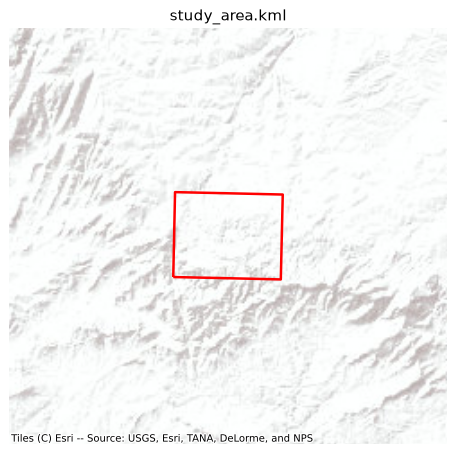

In [4]:
import contextily as ctx

ax = aoi_wgs.to_crs(3857).boundary.plot(figsize=(7, 6), color="red", lw=2)
x0, y0, x1, y1 = aoi_wgs.to_crs(3857).total_bounds
pad = 1.5 * (x1 - x0)
ax.set_xlim(x0 - pad, x1 + pad); ax.set_ylim(y0 - pad, y1 + pad)
try:
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTerrain, zoom=9, zorder=1)
except Exception as err:
    print(f"Basemap not available here ({type(err).__name__}); run online to see it.")
ax.set_title("study_area.kml"); ax.set_axis_off()

## Part 1: Download Sentinel-2 L2A from CDSE
> We are going to download Sentinel-2 L2A images from `27/06/2026` and `29/06/2026`.
>
> 1. Open the [CDSE browser](https://browser.dataspace.copernicus.eu)
> 2. Log in with your credentials
> 3. Define an area of interest by uploading a kml file. Click on the Create an area of interest icon in the top-right
>    corner and select Define Area of Interest (AOI). Then, in the File tab, browse to the `Lab_2` folder in your PC
>    and select the `study_area.kml` file
> 4. In the menu on the left, change the DATE from Single Date to Time Range
> 5. In the date range, set the starting date (From) to `27/06/2026` at `00:00` and the end date (Until) to
>    `29/06/2026` at `23:59`.
> 6. The Max. cloud coverage parameter limits the percentage of clouds in an image. Leave this parameter at `30%`
> 7. In the DATA COLLECTIONS section, make sure to select `Sentinel-2 L2A`
> 8. Click on Find products within selected time range to retrieve the available images
> 9. Click on the Download product icon to download the two images that cover the entire tile (approx. 1.1GB each).
>    Do not download the product has a partial cover of the tile
>
> Wait for the download, then copy and extract the downloaded contents to your `Lab_2` folder.

**In Python:** the CDSE Browser is a front end to the same catalogue the
[OData API](https://documentation.dataspace.copernicus.eu/APIs/OData.html) exposes, so steps 3–8 become one query
with the same settings: the area of interest from the KML, a 27–29 Jun 2026 time range, max. cloud cover 30 % and
the Sentinel-2 L2A collection. `cdse_download` (step 9) downloads, unzips into `LAB2_DATA` and deletes the zip.


The search is anonymous. Downloading needs a free CDSE account: set `CDSE_USER` and `CDSE_PASSWORD` in your
environment, or type them when asked. Accounts with two-factor authentication need a token from the CDSE dashboard
instead.

**Partial products.** A tile can come as a full product and as a partial one, from the edge of a satellite pass. The
lab says to skip partial ones. `tile_cover_pct` (footprint area ÷ the 109.8 km × 109.8 km tile) shows which are full.

In [5]:
import requests
from shapely import wkt as shapely_wkt
from shapely.geometry import shape

CDSE_CATALOGUE = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"
CDSE_TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
CDSE_ZIPPER = "https://zipper.dataspace.copernicus.eu/odata/v1/Products({id})/$value"
TILE_SIDE_M = 109_800


def cdse_search(area, start, end, max_cloud=MAX_CLOUD, product_type="S2MSI2A", top=50):
    """Products intersecting `area` (shapely, WGS84) sensed between `start` and `end` (YYYY-MM-DD, inclusive)."""
    area_wkt = shapely_wkt.dumps(area, rounding_precision=6)
    flt = (
        "Collection/Name eq 'SENTINEL-2'"
        " and Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'productType'"
        f" and att/OData.CSC.StringAttribute/Value eq '{product_type}')"
        " and Attributes/OData.CSC.DoubleAttribute/any(att:att/Name eq 'cloudCover'"
        f" and att/OData.CSC.DoubleAttribute/Value le {max_cloud})"
        f" and OData.CSC.Intersects(area=geography'SRID=4326;{area_wkt}')"
        f" and ContentDate/Start ge {start}T00:00:00.000Z and ContentDate/Start le {end}T23:59:59.999Z"
    )
    r = requests.get(CDSE_CATALOGUE, timeout=60, params={
        "$filter": flt, "$orderby": "ContentDate/Start", "$top": top, "$expand": "Attributes"})
    r.raise_for_status()
    rows = []
    for p in r.json()["value"]:
        attrs = {a["Name"]: a["Value"] for a in p.get("Attributes", [])}
        rows.append({"product": p["Name"], "id": p["Id"], "sensing": p["ContentDate"]["Start"],
                     "cloud_pct": attrs.get("cloudCover"), "size_GB": round(p.get("ContentLength", 0) / 1e9, 2),
                     "geometry": shape(p["GeoFootprint"])})
    if not rows:
        return gpd.GeoDataFrame(columns=["product", "id", "sensing", "cloud_pct", "size_GB", "tile_cover_pct"],
                                geometry=[], crs=4326)
    df = gpd.GeoDataFrame(rows, crs=4326)
    df["tile_cover_pct"] = (df.to_crs(TILE_EPSG).area / TILE_SIDE_M**2 * 100).round(1)
    return df


def cdse_token():
    user = os.environ.get("CDSE_USER") or input("CDSE e-mail: ")
    password = os.environ.get("CDSE_PASSWORD") or getpass.getpass("CDSE password: ")
    r = requests.post(CDSE_TOKEN_URL, timeout=60, data={
        "client_id": "cdse-public", "grant_type": "password", "username": user, "password": password})
    r.raise_for_status()
    return r.json()["access_token"]


def cdse_download(product_id, product_name, dest=DATA_DIR):
    """Download one product as .zip, unpack the .SAFE folder into `dest`, delete the zip.
    Skips products that are already there."""
    safe = Path(dest) / product_name
    if safe.exists():
        print(f"already here: {product_name}")
        return safe
    zpath = Path(dest) / (product_name.removesuffix(".SAFE") + ".zip")
    headers = {"Authorization": f"Bearer {cdse_token()}"}     # tokens expire after ~10 min: one per product
    with requests.get(CDSE_ZIPPER.format(id=product_id), headers=headers, stream=True, timeout=120) as r:
        r.raise_for_status()
        total, done = int(r.headers.get("Content-Length", 0)), 0
        with open(zpath, "wb") as f:
            for chunk in r.iter_content(chunk_size=8 << 20):
                f.write(chunk)
                done += len(chunk)
                print(f"\r{product_name[:60]}  {done / 1e9:5.2f} / {total / 1e9:.2f} GB", end="")
    print()
    with zipfile.ZipFile(zpath) as z:
        z.extractall(dest)
    zpath.unlink()
    return safe

In [6]:
area = aoi_wgs.geometry.union_all()
try:
    june = cdse_search(area, DATE1, DATE2)
    june = june[june["product"].str.contains(TILE)]
    june["local_copy"] = [(DATA_DIR / p).exists() for p in june["product"]]
    display(june.drop(columns=["geometry", "id"]))
except requests.RequestException as err:
    june = None
    print(f"CDSE not reachable ({type(err).__name__}); using the products already in {DATA_DIR}")

,product,sensing,cloud_pct,size_GB,tile_cover_pct,local_copy
0,S2C_MSIL2A_20260627T112111_N0512_R037_T29TPE_2...,2026-06-27T11:21:11.025000Z,5.724278,1.23,100.0,True
1,S2B_MSIL2A_20260629T110619_N0512_R137_T29TPE_2...,2026-06-29T11:06:19.024000Z,0.008197,0.53,38.2,False
2,S2A_MSIL2A_20260629T112131_N0512_R037_T29TPE_2...,2026-06-29T11:21:31.024000Z,0.017508,1.24,100.0,True


In [7]:
DOWNLOAD = False          # True -> fetch the full-tile products that are not here yet
FULL_TILE_MIN_PCT = 95

if DOWNLOAD and june is not None:
    for _, p in june[june["tile_cover_pct"] >= FULL_TILE_MIN_PCT].iterrows():
        cdse_download(p["id"], p["product"])

### The products: naming convention, folder structure, metadata
> Inspect the product folder. Sentinel-2 products follow a naming convention and are distributed in the SAFE
> (Standard Archive Format for Europe), which is a structured folder hierarchy that contains imagery, metadata and
> other auxiliary data.

**In Python:** `MMM_MSIXXX_YYYYMMDDHHMMSS_Nxxyy_ROOO_Txxxxx_YYYYMMDDHHMMSS.SAFE` splits into its fields with one
regular expression, a small `tree` function prints the folder hierarchy, and the metadata in `MTD_MSIL2A.xml` is
parsed into a table instead of read by eye:

In [8]:
safes = list_safes()
pd.DataFrame([{"folder": p.name, **parse_safe_name(p.name)} for p in safes]).set_index("folder")

,mission,level,sensing,baseline,orbit,tile,generated
folder,,,,,,,
S2A_MSIL2A_20260629T112131_N0512_R037_T29TPE_20260629T194611.SAFE,S2A,L2A,2026-06-29 11:21:31+00:00,05.12,037,T29TPE,2026-06-29 19:46:11+00:00
S2C_MSIL2A_20260627T112111_N0512_R037_T29TPE_20260627T150412.SAFE,S2C,L2A,2026-06-27 11:21:11+00:00,05.12,037,T29TPE,2026-06-27 15:04:12+00:00


In [9]:
def tree(path, depth=3, max_files=4, indent=""):
    """Print a folder tree, abbreviating long file lists."""
    entries = sorted((p for p in Path(path).iterdir() if not p.name.startswith(".")),
                     key=lambda p: (p.is_file(), p.name))
    dirs, files = [p for p in entries if p.is_dir()], [p for p in entries if p.is_file()]
    for d in dirs:
        print(f"{indent}{d.name}/")
        if depth > 1:
            tree(d, depth - 1, max_files, indent + "    ")
    for f in files[:max_files]:
        print(f"{indent}{f.name}")
    if len(files) > max_files:
        print(f"{indent}... (+{len(files) - max_files} more files)")

safe1, safe2 = find_safe(DATE1), find_safe(DATE2)
print(safe1.name)
tree(safe1, depth=5)

S2C_MSIL2A_20260627T112111_N0512_R037_T29TPE_20260627T150412.SAFE
DATASTRIP/
    DS_2CPS_20260627T150412_S20260627T112847/
        QI_DATA/
            FORMAT_CORRECTNESS.xml
            GENERAL_QUALITY.xml
            GEOMETRIC_QUALITY.xml
            RADIOMETRIC_QUALITY.xml
            ... (+1 more files)
        MTD_DS.xml
GRANULE/
    L2A_T29TPE_A009445_20260627T112847/
        AUX_DATA/
            AUX_CAMSFO
            AUX_ECMWFT
        IMG_DATA/
            R10m/
                T29TPE_20260627T112111_AOT_10m.jp2
                T29TPE_20260627T112111_B02_10m.jp2
                T29TPE_20260627T112111_B02_10m.jp2.aux.xml
                T29TPE_20260627T112111_B03_10m.jp2
                ... (+8 more files)
            R20m/
                T29TPE_20260627T112111_AOT_20m.jp2
                T29TPE_20260627T112111_B01_20m.jp2
                T29TPE_20260627T112111_B02_20m.jp2
                T29TPE_20260627T112111_B03_20m.jp2
                ... (+13 more files)
            R60m

In [10]:
meta = {p.name[:26]: safe_metadata(p) for p in (safe1, safe2)}
table = pd.DataFrame(meta).drop(index="boa_offset")
table.loc["BOA offset (B02/B03/B04/B08)"] = [
    "/".join(str(m["boa_offset"][b]) for b in BANDS) for m in meta.values()]
table

,S2C_MSIL2A_20260627T112111,S2A_MSIL2A_20260629T112131
spacecraft,Sentinel-2C,Sentinel-2A
sensing_start,2026-06-27T11:21:11.025Z,2026-06-29T11:21:31.024Z
processing_baseline,05.12,05.12
cloud_cover_pct,5.724278,0.017508
quantification,10000,10000
sun_zenith_deg,21.265694,21.361485
sun_azimuth_deg,137.71746,137.808
BOA offset (B02/B03/B04/B08),-1000/-1000/-1000/-1000,-1000/-1000/-1000/-1000


**Reflectance = (DN + BOA_ADD_OFFSET) / QUANTIFICATION_VALUE.** Both products are baseline 05.12, so each band has an
offset of −1000 and a quantification value of 10 000. The composites below keep the raw DNs, like the ArcGIS
workflow, and the offset is only removed where it matters: computing NDVI.

In [11]:
OFFSET = {b: meta[safe1.name[:26]]["boa_offset"][b] for b in BANDS}
QUANT = meta[safe1.name[:26]]["quantification"]
assert all(m["boa_offset"][b] == OFFSET[b] for m in meta.values() for b in BANDS), "products scaled differently"
assert all(m["quantification"] == QUANT for m in meta.values())


def to_reflectance(dn, band):
    """DN -> surface reflectance for one band; NODATA -> NaN."""
    r = (dn.astype("float32") + OFFSET[band]) / QUANT
    r[dn == NODATA] = np.nan
    return r

print("offsets:", OFFSET, " quantification:", QUANT)

offsets: {'B02': -1000, 'B03': -1000, 'B04': -1000, 'B08': -1000}  quantification: 10000


## Part 2: Pre-processing

The 27 Jun image has clouds and cloud shadows over the study area. The SCL marks them, so they get masked and the
holes are filled from 29 Jun. First, the whole tile on both dates, with the study area in red:

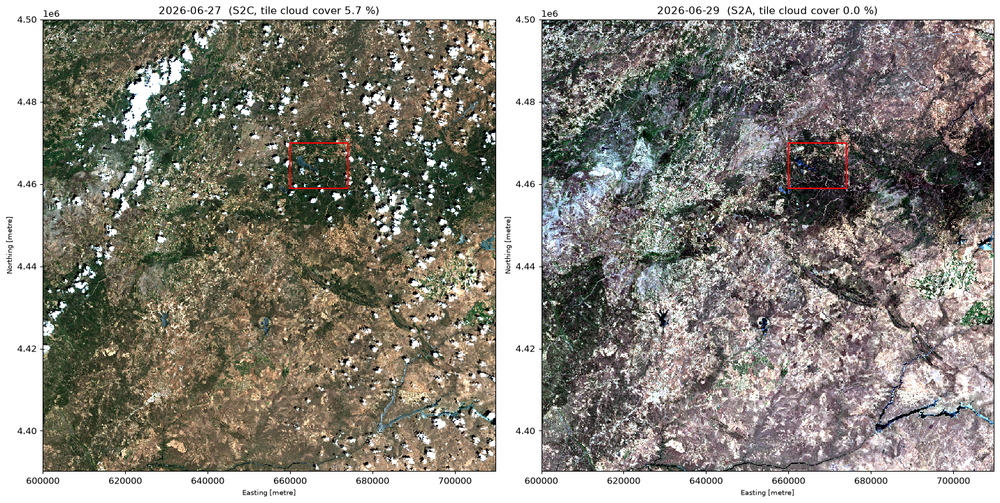

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, safe, date in zip(axes, (safe1, safe2), (DATE1, DATE2)):
    rgb = []
    for b in ("B04", "B03", "B02"):
        arr, ext = read_preview(band_path(safe, b))
        rgb.append(arr)
    ax.imshow(as_rgba(stretch(np.stack(rgb), 1, 95)), extent=ext)      # low pmax: clouds are very bright
    aoi.boundary.plot(ax=ax, color="red", lw=1.5)
    ax.set_title(f"{date}  ({safe.name[:3]}, tile cloud cover {meta[safe.name[:26]]['cloud_cover_pct']:.1f} %)")
plt.tight_layout()

### Composite + clip (steps 1–4, 7)
> 1. Load the Bands B2, B3, B4 and B8 (10m) from the first date (27/06/2026) in ArcGIS
> 2. Create a multiband composite (Imagery > Process > Composite)
>
>    > Remember to order the bands correctly to preserve their natural order.
> 3. Rename the composite to `Composite_date1`
> 4. Adjust the symbology to create a **True Color** composite
>
>    > Red: Band 3; Green: Band 2; Blue: Band 1
>
> …
>
> 7. Clip the composite to the study area
>    - Search for the Clip Raster tool in Analysis > Tools
>    - In the *Input Raster* field, select `Composite_date1`
>    - In the *Output Extent* field, select the `study_area`
>    - In the *Output Raster Dataset* field, name the output `Composite_date1_Clip`

**In Python:** `Composite` and `Clip Raster` become one windowed read. The window is snapped outward to the 20 m grid, so the 10 m
bands and the 20 m SCL cover exactly the same ground: 2 × 2 10 m pixels per SCL pixel. Step 4's symbology is `true_colour()`, which shows bands 3, 2, 1 as red, green, blue.

clip bounds: (np.float64(660000.0), np.float64(4459000.0), np.float64(674000.0), np.float64(4470000.0))
Composite_date1_Clip: (4, 1100, 1400) uint16


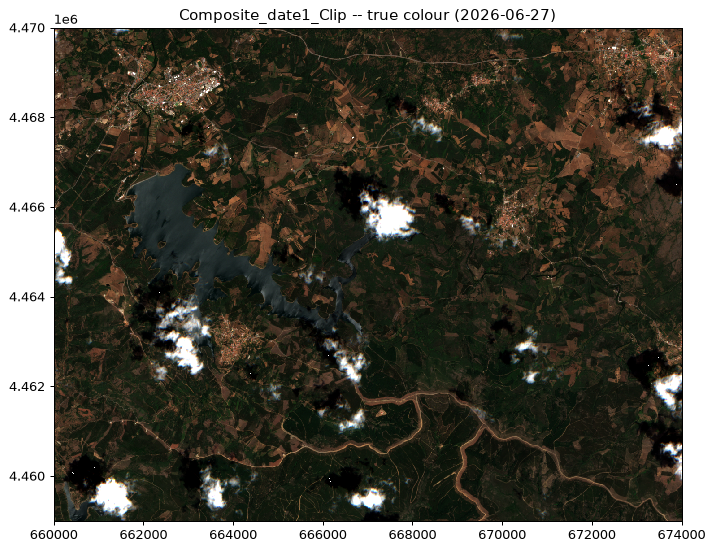

In [13]:
with rasterio.open(band_path(safe1, "SCL", 20)) as src:
    BOUNDS = snap_bounds(aoi.total_bounds, src.transform, step=20)
print("clip bounds:", BOUNDS)

comp1, transform, crs = composite(safe1, BOUNDS)          # Composite_date1_Clip
print("Composite_date1_Clip:", comp1.shape, comp1.dtype)
EXTENT = extent_of(comp1[0], transform)

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(true_colour(comp1), extent=EXTENT)
ax.set_title(f"Composite_date1_Clip -- true colour ({DATE1})");

### Scene Classification Layer (steps 5, 8)
> 5. Add to the map the *Scene Classification Layer (SCL)* available in:
>    `IMG_DATA/R20m/T29TPE_20260627T112111_SCL_20m.jp2`
>
> …
>
> 8. Clip the SCL to the study area
>    - Search for the Clip Raster tool in Analysis > Tools
>    - In the *Input Raster* field, select the `T29TPE_20260627T112111_SCL_20m` layer
>    - In the *Output Extent* field, select the `study_area`
>    - In the *Output Raster Dataset* field, name the output `SCL_date1_Clip`

**In Python:** the same windowed read as the composite (`read_clip`), on the 20 m grid. The SCL labels every pixel
with one of 12 classes. The colours are ESA's standard SCL palette, and a table gives each class's share on both dates.

SCL_date1_Clip: (550, 700) at 20.0 m


,class,2026-06-27 %,2026-06-29 %
2,Dark area / topographic shadow,0.27,0.37
3,Cloud shadow,6.46,0.11
4,Vegetation,70.54,78.52
5,Not vegetated,15.47,17.38
6,Water,1.67,2.99
7,Unclassified,1.59,0.62
8,"Cloud, medium probability",2.87,0.01
9,"Cloud, high probability",1.12,0.00
10,Thin cirrus,0.00,0.01


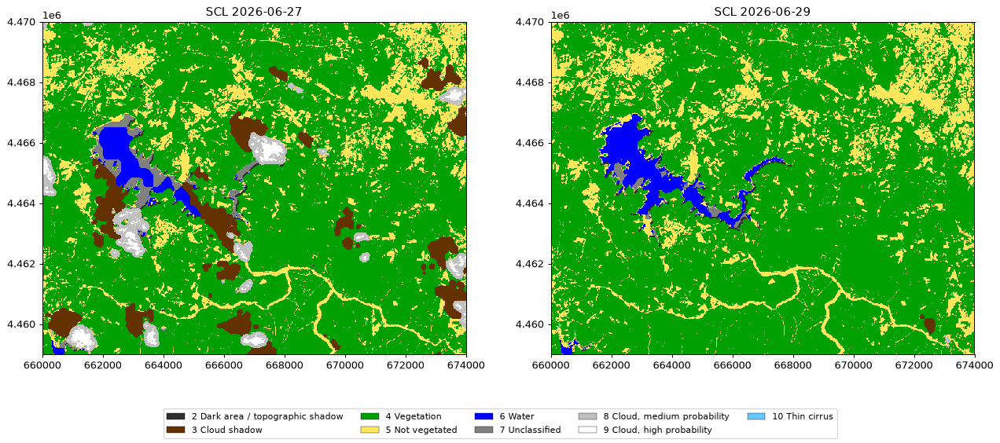

In [14]:
SCL_CLASSES = {  # value: (label, ESA colour)
    0: ("No data", "#000000"),               1: ("Saturated / defective", "#ff0000"),
    2: ("Dark area / topographic shadow", "#2f2f2f"), 3: ("Cloud shadow", "#643200"),
    4: ("Vegetation", "#00a000"),            5: ("Not vegetated", "#ffe65a"),
    6: ("Water", "#0000ff"),                 7: ("Unclassified", "#808080"),
    8: ("Cloud, medium probability", "#c0c0c0"), 9: ("Cloud, high probability", "#ffffff"),
    10: ("Thin cirrus", "#64c8ff"),          11: ("Snow / ice", "#ff96ff"),
}
SCL_CMAP = ListedColormap([c for _, c in SCL_CLASSES.values()])
SCL_NORM = BoundaryNorm(np.arange(-0.5, 12.5), SCL_CMAP.N)


def scl_table(**scl_by_date):
    """% of pixels per SCL class, one column per date; classes absent everywhere are dropped."""
    tbl = pd.DataFrame({"class": [label for label, _ in SCL_CLASSES.values()]}, index=list(SCL_CLASSES))
    for date, scl in scl_by_date.items():
        vals, counts = np.unique(scl, return_counts=True)
        tbl[f"{date} %"] = pd.Series(100 * counts / counts.sum(), index=vals)
    num = tbl.columns[1:]
    tbl[num] = tbl[num].fillna(0).round(2)
    return tbl[(tbl[num] > 0).any(axis=1)]


scl1, scl_transform, _ = read_clip(band_path(safe1, "SCL", 20), BOUNDS)    # SCL_date1_Clip
scl2, _, _ = read_clip(band_path(safe2, "SCL", 20), BOUNDS)
print("SCL_date1_Clip:", scl1.shape, "at", scl_transform.a, "m")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, scl, date in zip(axes, (scl1, scl2), (DATE1, DATE2)):
    ax.imshow(scl, cmap=SCL_CMAP, norm=SCL_NORM, extent=EXTENT)
    ax.set_title(f"SCL {date}")
present = sorted(set(np.unique(scl1)) | set(np.unique(scl2)))
fig.legend(handles=[Patch(fc=SCL_CLASSES[v][1], ec="k", lw=0.3, label=f"{v} {SCL_CLASSES[v][0]}") for v in present],
           loc="lower center", ncol=5, fontsize=9)
plt.subplots_adjust(bottom=0.14)
display(scl_table(**{DATE1: scl1, DATE2: scl2}))

### Cloud mask (steps 9–11)
> 9. Create a cloud and cloud shadow mask using the SCL layer
>    - Search for the Raster Calculator in Analysis > Tools
>    - Use the following expression to create a binary mask (a raster with zeros and ones) masks (set the pixel value
>      to zero) the invalid pixels (e.g. clouds, shadows, saturated/defective pixels)
>      `(( "SCL_date1_Clip">3)&( "SCL_date1_Clip" <=7))|( "SCL_date1_Clip"==11)`
>    - Name the *Output raster* as `mask_date1_temp`
> 10. Set the zeros to NoData in the resulting binary mask raster
>     - Search for the Raster Calculator in Analysis > Tools
>     - Use the `SetNull` operator as shown: `SetNull("mask_date1_temp"==0, 1)`
>     - Name the *Output raster* as `mask_date1_temp2`
> 11. Resample the mask from 20 m to 10 m
>     - Search for the Resample tool in Analysis > Tools
>     - Select `mask_date1_temp2` as the *Input Raster*
>     - Name the *Output Raster Dataset* as `mask_date1_final`
>     - Change the spatial resolution, defining *X* and *Y* as `10`
>     - Leave the *Resampling Techinique* as `Nearest Neighbors`

**In Python:** `np.isin(SCL, [4, 5, 6, 7, 11])` is the same expression (the cell asserts it). It keeps vegetation,
not-vegetated, water, unclassified and snow (classes 4–7, 11). It drops no data, defective, dark/shadow, cloud
shadow, both cloud classes and cirrus.

- **Step 10 (`SetNull`)** turns the zeros into NoData. In numpy, the boolean mask is already that: `False` = NoData.
- **Not in the lab: `BUFFER_PX`.** The SCL under-detects cloud edges and thin haze, and the masked composite below
  shows bright halos around the masked clouds. Growing the mask by 2 SCL pixels (40 m) removes part of that,
  masking 13.7 % instead of 10.7 % here. A thin patch the SCL didn't flag at all survives any buffer.
- **Step 11** resamples the mask from 20 m to 10 m with nearest neighbour. `rasterio.warp.reproject` is the same
  Resample tool. Because both grids are aligned, it is identical to repeating every 20 m pixel 2 × 2, and the
  `assert` checks that.

valid: 89.3% of the study area;  masked out: 10.7%


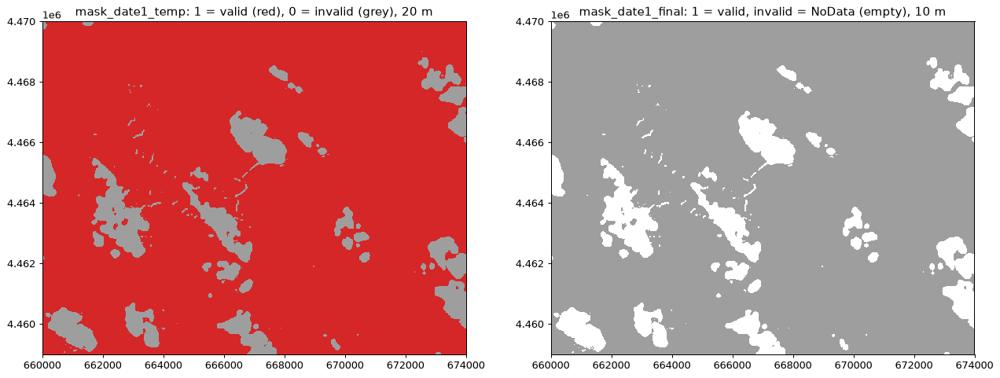

In [15]:
VALID_SCL = [4, 5, 6, 7, 11]
BUFFER_PX = 0             # grow the invalid area by this many 20 m SCL pixels; 0 = the lab's mask

mask20 = np.isin(scl1, VALID_SCL)                          # mask_date1_temp (True = keep)
assert np.array_equal(mask20, ((scl1 > 3) & (scl1 <= 7)) | (scl1 == 11))   # the lab's expression
if BUFFER_PX:
    mask20 &= ~binary_dilation(~mask20, iterations=BUFFER_PX)

mask10 = np.zeros(comp1.shape[1:], dtype="uint8")          # mask_date1_final
reproject(mask20.astype("uint8"), mask10, src_transform=scl_transform, src_crs=crs,
          dst_transform=transform, dst_crs=crs, resampling=Resampling.nearest)
mask10 = mask10.astype(bool)
assert np.array_equal(mask10, np.kron(mask20, np.ones((2, 2), bool)))

print(f"valid: {mask10.mean():.1%} of the study area;  masked out: {(~mask10).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
axes[0].imshow(mask20, cmap=ListedColormap(["#9e9e9e", "#d62728"]), extent=EXTENT)
axes[0].set_title("mask_date1_temp: 1 = valid (red), 0 = invalid (grey), 20 m")
axes[1].imshow(np.ma.masked_array(mask10, ~mask10), cmap=ListedColormap(["#9e9e9e"]), extent=EXTENT)
axes[1].set_title("mask_date1_final: 1 = valid, invalid = NoData (empty), 10 m");

### Extract by mask (step 12)
> 12. Mask the composite with the final cloud mask
>     - Search for the Extract by Mask tool in Analysis > Tools
>     - In the *Input raster* field, select the `Composite_date1_Clip`
>     - In the *Input raster or feature mask data*, select `mask_date1_final`
>     - Name the *Output raster* as `Composite_date1_masked`
>     - For *Extraction Area*, select `Inside`

**In Python:** `np.where(mask10, comp1, NODATA)`: keep the pixel where the mask is valid, NoData elsewhere.

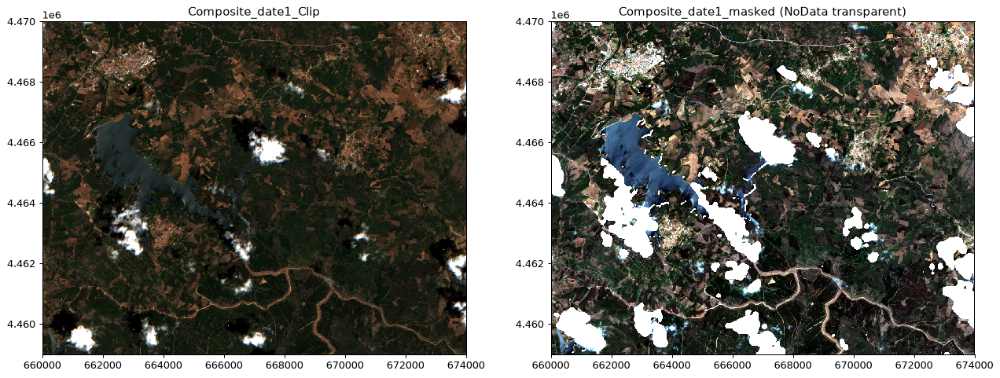

In [16]:
comp1_masked = np.where(mask10, comp1, NODATA).astype(comp1.dtype)    # Composite_date1_masked

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
axes[0].imshow(true_colour(comp1), extent=EXTENT)
axes[0].set_title("Composite_date1_Clip")
axes[1].imshow(true_colour(comp1_masked), extent=EXTENT)
axes[1].set_title("Composite_date1_masked (NoData transparent)");

### Fill the gaps from the second date
> 1. Load the Bands B2, B3, B4 and B8 (10m) from the second date (29/06/2026) in ArcGIS
> 2. Create a composite (*remember to use bands in the correct order*)
> 3. Rename the composite to `Composite_date2`
> 4. Clip the composite to the study area, naming the output as `Composite_date2_Clip`
> 5. Create a Mosaic
>    - In Imagery tab, select Raster Functions
>    - Search for the Mosaic Rasters tool
>    - Select the `Composite_date1_masked` and `Composite_date2_Clip`
>    - In the *Operation* field, choose `Mean`
>
>      > By choosing `Mean`, pixel values in the mosaic will be the average of pixels in the input composites.

**In Python:** steps 1–4 are the same windowed read as for the first date. `Mosaic Rasters` with **Mean** is
`np.nanmean` over the two dates with NoData set to NaN. It averages the inputs wherever more than one has a value,
and ignores NoData. So:

- pixels clear on 27 Jun get the average of both dates;
- pixels masked on 27 Jun take the 29 Jun value alone.

The lab doesn't mask 29 Jun. That image is almost cloud-free here, but whatever its SCL flags still goes into the
mosaic. Set `MASK_DATE2 = True` to mask it too; pixels invalid on both dates then stay NoData.

In [17]:
MASK_DATE2 = False

comp2, transform2, _ = composite(safe2, BOUNDS)            # Composite_date2_Clip
assert transform2 == transform
mask2_10 = np.kron(np.isin(scl2, VALID_SCL), np.ones((2, 2), bool))
print(f"29 Jun pixels its own SCL would mask: {(~mask2_10).mean():.2%}"
      + ("  -> masked" if MASK_DATE2 else "  -> kept (as in the lab)"))
if MASK_DATE2:
    comp2 = np.where(mask2_10, comp2, NODATA).astype(comp2.dtype)

# A few very dark water pixels have DN 0 in single bands -- the same value as NoData -- so
# NoData is handled per band: each band of the mosaic averages whichever dates have a value.
stack = np.stack([comp1_masked, comp2]).astype("float32")  # [date, band, row, col]
stack[stack == NODATA] = np.nan
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)         # "mean of empty slice" where both are NoData
    mean = np.nanmean(stack, axis=0)                        # Mosaic Rasters, operation = Mean
mosaic = np.where(np.isnan(mean), NODATA, np.round(mean)).astype("uint16")

has1, has2 = comp1_masked[0] != NODATA, comp2[0] != NODATA
source = pd.Series({"mean of both dates": (has1 & has2).mean(), "29 Jun only": (~has1 & has2).mean(),
                    "27 Jun only": (has1 & ~has2).mean(), "NoData": (~has1 & ~has2).mean()})
display((100 * source).round(2).rename("% of pixels").to_frame())

29 Jun pixels its own SCL would mask: 0.49%  -> kept (as in the lab)


,% of pixels
mean of both dates,89.28
29 Jun only,10.72
27 Jun only,0.00
NoData,0.00


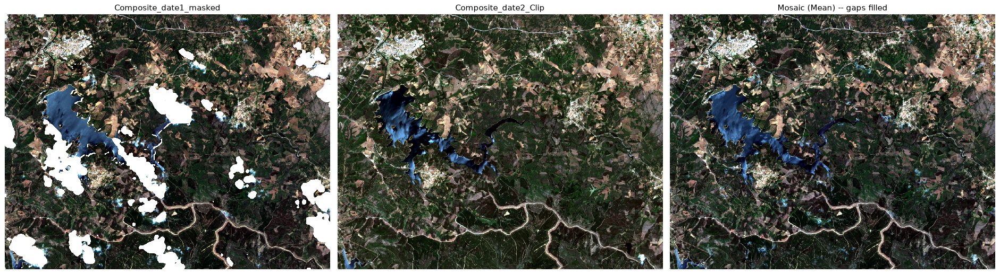

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, arr, title in zip(axes, (comp1_masked, comp2, mosaic),
                          ("Composite_date1_masked", "Composite_date2_Clip", "Mosaic (Mean) -- gaps filled")):
    ax.imshow(true_colour(arr), extent=EXTENT)
    ax.set_title(title); ax.set_axis_off()
plt.tight_layout()

**Is averaging two dates harmless?** Where both dates are clear, here is how much they differ per band (in
reflectance units). Two days apart this mostly reflects sensor (S2C vs S2A), illumination and residual atmosphere, not
real change.

In [19]:
rows = {}
for i, b in enumerate(BANDS):
    both = (comp1_masked[i] != NODATA) & (comp2[i] != NODATA)
    r1, r2 = to_reflectance(comp1[i][both], b), to_reflectance(comp2[i][both], b)
    rows[b] = {"mean 27 Jun": r1.mean(), "mean 29 Jun": r2.mean(), "mean |diff|": np.abs(r1 - r2).mean(),
               "corr": np.corrcoef(r1, r2)[0, 1]}
pd.DataFrame(rows).T.round(4)

,mean 27 Jun,mean 29 Jun,mean |diff|,corr
B02,0.0400,0.0367,0.0053,0.8398
B03,0.0631,0.0589,0.0061,0.8891
B04,0.0652,0.0619,0.0062,0.9525
B08,0.2721,0.2611,0.0149,0.9721


## Part 3: Feature engineering
> Two composites must be exported as GeoTiffs:
>
> - A Baseline composite (RGB + NIR)
> - An NDVI composite (RGB + NIR + NDVI)
>
> For the Baseline composite, simply export the Mosaic created in the previous section:
>
> - Right click > Data > Export Raster
> - Name it `Composite_Baseline.tif`
> - Leave the other fields as default

**In Python:** `write_tif` writes the mosaic array with the study-area grid. The two GeoTIFFs for Lab 3:

- **`Composite_Baseline.tif`**: the mosaic as Blue, Green, Red, NIR; raw DNs, uint16, NoData 0.
- **`Composite_NDVI.tif`**: Blue, Green, Red, NIR, NDVI × 10 000, as **16-bit signed** (int16).

In [20]:
DESCR = ["B02 Blue", "B03 Green", "B04 Red", "B08 NIR"]
baseline_path = write_tif(OUT_DIR / "Composite_Baseline.tif", mosaic, crs, transform, NODATA, DESCR)

wrote Composite_Baseline.tif: 4 bands, 1400 x 1100 px, uint16, 10.2 MB


### NDVI
> 1. Compute NDVI
>    - Select the Baseline Composite in the Contents pane
>    - Imagery > Indices > NDVI
>    - For *Near Infrared Band Index*, select `4 - Band 4`
>    - For *Red Band Index*, select `3 - Band 3`
> 2. The resulting NDVI layer is in the [-1, 1] scale. In order to match the Baseline Composite scale, it needs to be
>    multiplied by `10,000`
>
>    > Tip: Use the **Band Arithmetic** tool

**In Python:** (NIR − Red) / (NIR + Red) on bands 4 and 3 of the mosaic, in numpy; the × 10 000 happens when the
composite is written, below. As in Lab 1,
NDVI is computed on reflectance (offset removed). ArcGIS's raw-DN version comes out systematically lower,
(n − r) / (n + r + 0.2) in reflectance terms.

NDVI  p1 -0.159   median 0.672   p99 0.901


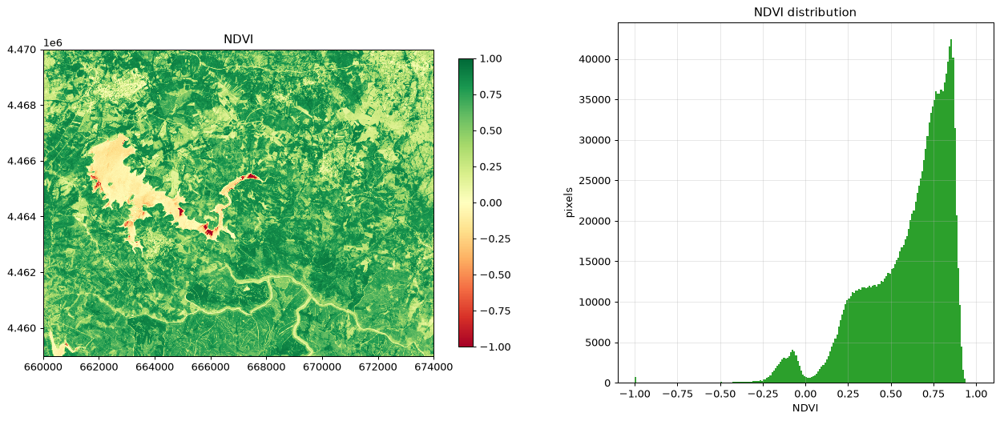

In [22]:
NDVI_FROM_RAW_DN = False

red_dn, nir_dn = mosaic[2], mosaic[3]
if NDVI_FROM_RAW_DN:
    red, nir = red_dn.astype("float32"), nir_dn.astype("float32")
else:
    red, nir = to_reflectance(red_dn, "B04"), to_reflectance(nir_dn, "B08")
with np.errstate(divide="ignore", invalid="ignore"):
    ndvi = np.clip((nir - red) / (nir + red), -1, 1)
ndvi[(red_dn == NODATA) | (nir_dn == NODATA)] = np.nan

v = ndvi[np.isfinite(ndvi)]
print(f"NDVI  p1 {np.percentile(v, 1):.3f}   median {np.median(v):.3f}   p99 {np.percentile(v, 99):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
im = axes[0].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1, extent=EXTENT)
plt.colorbar(im, ax=axes[0], shrink=0.8)
axes[0].set_title("NDVI")
axes[1].hist(v, bins=200, range=(-1, 1), color="tab:green")
axes[1].set(xlabel="NDVI", ylabel="pixels", title="NDVI distribution"); axes[1].grid(alpha=0.3)

In [23]:
ndvi

array([[0.35904828, 0.37918994, 0.46388984, ..., 0.31453636, 0.43944862,
        0.5980291 ],
       [0.3872549 , 0.36501598, 0.4045404 , ..., 0.2982456 , 0.5281757 ,
        0.54291046],
       [0.40571424, 0.32808617, 0.3365539 , ..., 0.2766898 , 0.5350318 ,
        0.5531964 ],
       ...,
       [0.6616915 , 0.5741526 , 0.30331314, ..., 0.37212276, 0.38244715,
        0.40656567],
       [0.67907566, 0.45539907, 0.23667568, ..., 0.36529967, 0.39827532,
        0.40420118],
       [0.69026554, 0.42512074, 0.26469183, ..., 0.3772756 , 0.41861206,
        0.40501112]], shape=(1100, 1400), dtype=float32)

### NDVI composite (int16)
> 3. Create the NDVI composite (Bands: Blue, Green, Red, NIR, NDVI)
>    - Select the scaled NDVI and the Baseline Composite layers in the Contents pane. To ensure the correct band order
>      in the target composite, place the Baseline Composite on top
> 4. Export the NDVI composite as a GeoTiff file. Name it `Composite_NDVI.tif`
>    - Set the *Pixel Type* to `16 Bit Signed`

**In Python:** `np.concatenate` puts NDVI × 10 000 after the four bands, so the band order is fixed by the code, not
by the layer order in a pane. 16-bit signed covers −32 768…32 767. NDVI × 10 000 fits easily. The DN bands fit as long as nothing exceeds
32 767, which the cell checks. NoData becomes −32 768, the usual int16 choice, because a GeoTIFF has one NoData value
for all bands and 0 is a valid NDVI.

In [24]:
I16_NODATA = -32768
ndvi_i16 = np.where(np.isfinite(ndvi), np.round(ndvi * 10_000), I16_NODATA).astype("int16")

over = int((mosaic > np.iinfo("int16").max).sum())
print(f"DN values above 32767 (clipped): {over}")
dn = mosaic.astype("int32")
bands_i16 = np.where(dn == NODATA, I16_NODATA, np.minimum(dn, 32767)).astype("int16")

ndvi_stack = np.concatenate([bands_i16, ndvi_i16[None]])
ndvi_path = write_tif(OUT_DIR / "Composite_NDVI.tif", ndvi_stack, crs, transform, I16_NODATA,
                      DESCR + ["NDVI x 10000"])

DN values above 32767 (clipped): 0
wrote Composite_NDVI.tif: 5 bands, 1400 x 1100 px, int16, 13.6 MB


## Exercise: summer + winter temporal composite
> Download a cloud-free image from the winter (e.g. `22/02/2026`) and create a temporal composite by stacking it to
> the Baseline Composite.
>
> The temporal composite should have the following bands:
>
> - Band 1: Blue (Baseline Composite)
> - Band 2: Green (Baseline Composite)
> - Band 3: Red (Baseline Composite)
> - Band 4: NIR (Baseline Composite)
> - Band 5: Blue (Winter image)
> - Band 6: Green (Winter image)
> - Band 7: Red (Winter image)
> - Band 8: NIR (Winter image)
>
> Export the composite as `Composite_temporal.tif`.

**In Python:** the first cell searches CDSE around `WINTER_DATE`; set `DOWNLOAD_WINTER = True` to fetch the product
you pick. "Cloud-free" is judged by the SCL *inside the study area*, not by the tile-wide cloud percentage. The winter
bands are read through the same study-area window, so they line up with the Baseline pixel for pixel, and
`np.concatenate` stacks them as bands 5–8.

In [ ]:
DOWNLOAD_WINTER = False
WINTER_PRODUCT = None     # optional: exact product name to download; default = least cloudy full tile on WINTER_DATE

try:
    winter = cdse_search(area, WINTER_DATE, WINTER_DATE, max_cloud=MAX_CLOUD)
    winter = winter[winter["product"].str.contains(TILE)].sort_values("cloud_pct")
    display(winter.drop(columns=["geometry", "id"]))
    if DOWNLOAD_WINTER:
        full = winter[winter["tile_cover_pct"] >= FULL_TILE_MIN_PCT]
        pick = full[full["product"] == WINTER_PRODUCT] if WINTER_PRODUCT else full.head(1)
        for _, p in pick.iterrows():
            cdse_download(p["id"], p["product"])
except requests.RequestException as err:
    print(f"CDSE not reachable ({type(err).__name__})")

In [ ]:
safe_w = find_safe(WINTER_DATE)
if safe_w is None:
    print(f"No {TILE} product from {WINTER_DATE} in {DATA_DIR} yet -- download it above, then re-run this cell.")
else:
    comp_w, transform_w, _ = composite(safe_w, BOUNDS)
    assert transform_w == transform
    scl_w, _, _ = read_clip(band_path(safe_w, "SCL", 20), BOUNDS)
    print(f"{safe_w.name}\ninvalid (per SCL) inside the study area: {(~np.isin(scl_w, VALID_SCL)).mean():.2%}")
    display(scl_table(**{WINTER_DATE: scl_w}))

    temporal = np.concatenate([mosaic, comp_w])
    w_tag = WINTER_DATE.replace("-", "")
    temporal_path = write_tif(OUT_DIR / "Composite_temporal.tif", temporal, crs, transform, NODATA,
                              [f"{d} summer" for d in DESCR] + [f"{d} winter {w_tag}" for d in DESCR])

    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
    axes[0].imshow(true_colour(mosaic), extent=EXTENT); axes[0].set_title("Summer (Baseline mosaic)")
    axes[1].imshow(true_colour(comp_w), extent=EXTENT); axes[1].set_title(f"Winter ({WINTER_DATE})")

## Outputs

In [ ]:
rows = []
for p in sorted(OUT_DIR.glob("Composite_*.tif")):
    with rasterio.open(p) as src:
        rows.append({"file": p.name, "bands": src.count, "dtype": src.dtypes[0], "nodata": src.nodata,
                     "size": f"{src.width} x {src.height}", "MB": round(p.stat().st_size / 1e6, 1),
                     "band names": ", ".join(src.descriptions)})
pd.DataFrame(rows).set_index("file")